<a href="https://colab.research.google.com/github/curtismutuma-rgb/AI-for-Science-and-Engineering-Short-Course/blob/main/Week5_Supervised_Model_ChestMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment: Building Your First Supervised Machine Learning Model

## Project context

This notebook continues my medical disease-identification project using ChestMNIST. The dataset contains chest X-ray images with multiple report-mined disease labels. For a first supervised model, I focus on one label: whether the image has the dataset's **pneumonia** label. The goal is to compare two models on this binary classification task. This is an educational exercise, not a clinical diagnostic tool.


## Target, features, task, and split

- **Target/output (`y`):** the pneumonia indicator in ChestMNIST's multi-label vector (1 = pneumonia label present; 0 = pneumonia label not recorded). A zero is not a confirmed clinical negative because the dataset labels are report-mined.
- **Features (`X`):** all 784 pixel-intensity values from each 28 × 28 grayscale X-ray, flattened into one numeric vector and scaled from 0–255 to 0–1.
- **Problem type:** binary classification, because the target is one of two categories (0 or 1), not a continuous measurement.
- **Training and test data:** use ChestMNIST's official training and test splits to keep the test set separate. To keep model training manageable in Colab, use a stratified random subset of up to 12,000 images from the official training split; evaluate on the full official test split.

The official MedMNIST package is used to download ChestMNIST in Colab. The dataset is a low-resolution educational benchmark and is not intended for clinical use. See the [official MedMNIST project](https://medmnist.com/) and [data record](https://doi.org/10.5281/zenodo.10519652).


In [2]:
# Install the official package used to download ChestMNIST.
!pip -q install medmnist

In [3]:
# Import the dataset, data-splitting helper, and model evaluation tools.
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from medmnist import ChestMNIST, INFO
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)
import matplotlib.pyplot as plt

# Download the official training and test partitions.
train_data = ChestMNIST(split="train", download=True)
test_data = ChestMNIST(split="test", download=True)

# Find the pneumonia target column by its name in the dataset metadata.
label_map = INFO["chestmnist"]["label"]
label_names = [label_map[str(i)] for i in range(len(label_map))]
pneumonia_index = label_names.index("pneumonia")

# Extract the binary pneumonia target from the multi-label arrays.
y_train_all = np.asarray(train_data.labels).reshape(len(train_data), -1).astype(int)[:, pneumonia_index]
y_test = np.asarray(test_data.labels).reshape(len(test_data), -1).astype(int)[:, pneumonia_index]

# Select a stratified subset of the official training data for a faster first model.
max_train_samples = 12000
all_train_indices = np.arange(len(train_data))
if len(all_train_indices) > max_train_samples:
    train_indices, _ = train_test_split(
        all_train_indices,
        train_size=max_train_samples,
        random_state=42,
        stratify=y_train_all,
    )
else:
    train_indices = all_train_indices

# Flatten each grayscale image to 784 features and scale pixel values to 0–1.
train_pixels = np.asarray(train_data.imgs).reshape(len(train_data), -1)
test_pixels = np.asarray(test_data.imgs).reshape(len(test_data), -1)
X_train = train_pixels[train_indices].astype(np.float32) / 255.0
y_train = y_train_all[train_indices]
X_test = test_pixels.astype(np.float32) / 255.0

print(f"Training images used: {len(X_train):,}")
print(f"Official test images: {len(X_test):,}")
print(f"Number of pixel features per image: {X_train.shape[1]}")
print(f"Positive pneumonia-label share — train: {y_train.mean():.3f}; test: {y_test.mean():.3f}")

100%|██████████| 82.8M/82.8M [00:51<00:00, 1.62MB/s]


Training images used: 12,000
Official test images: 22,433
Number of pixel features per image: 784
Positive pneumonia-label share — train: 0.013; test: 0.011


## Models

1. **Logistic Regression** provides a simple linear classification baseline.
2. **Random Forest** can model nonlinear patterns and interactions between pixels.

Both models use class weighting to account for the possible imbalance between pneumonia and non-pneumonia labels. The same training and test data are used for a fair comparison.

In [4]:
# Define two supervised classifiers with fixed settings for this comparison.
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=300,
        solver="liblinear",
        class_weight="balanced",
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=60,
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced_subsample",
        n_jobs=-1,
        random_state=42,
    ),
}

# Fit each model on the training data and predict labels and probabilities for test images.
metric_rows = {}
test_predictions = {}
test_probabilities = {}
for model_name, model in models.items():
    print(f"Training {model_name}...")
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    test_predictions[model_name] = predictions
    test_probabilities[model_name] = probabilities
    metric_rows[model_name] = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

# Display the test-set metrics side by side.
metrics_df = pd.DataFrame(metric_rows).T
display(metrics_df.round(3))

Training Logistic Regression...
Training Random Forest...


,Accuracy,Balanced accuracy,Precision,Recall,F1 score,ROC-AUC
Logistic Regression,0.810,0.540,0.015,0.264,0.029,0.576
Random Forest,0.979,0.513,0.037,0.037,0.037,0.651


/tmp/ipykernel_720/3532996576.py:15: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


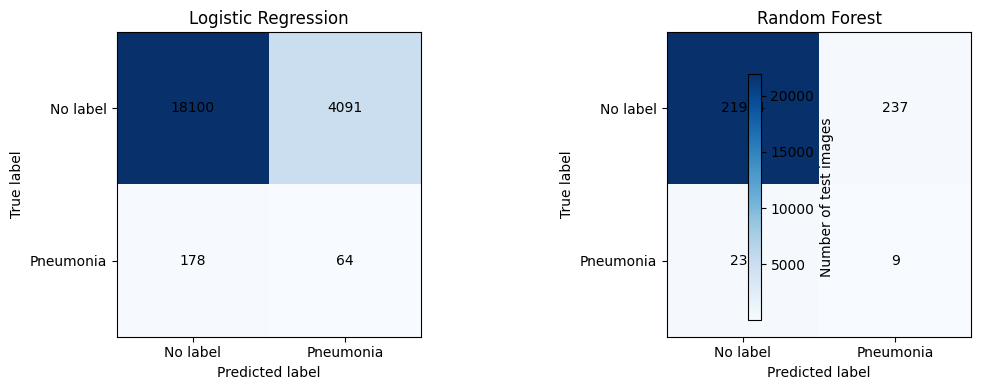

In [5]:
# Plot a confusion matrix for each model to show correct and incorrect predictions.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, (model_name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    image = axis.imshow(matrix, cmap="Blues")
    axis.set_title(model_name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")
    axis.set_xticks([0, 1], ["No label", "Pneumonia"])
    axis.set_yticks([0, 1], ["No label", "Pneumonia"])
    for row in range(2):
        for col in range(2):
            axis.text(col, row, str(matrix[row, col]), ha="center", va="center")
fig.colorbar(image, ax=axes, shrink=0.8, label="Number of test images")
plt.tight_layout()
plt.show()

## Compare performance and discuss results

The metrics table and confusion matrices above show how the models performed on the held-out test images. The next cell generates a short comparison using the metrics from your run. For this imbalanced medical-label task, consider recall (how many positive labels were found), precision (how many positive predictions were correct), and F1 together; accuracy alone can be misleading. A higher recall can come with more false positives. These results measure agreement with the dataset labels only and do not establish clinical usefulness.


In [6]:
# Create a concise run-specific comparison of the two models.
lr = metrics_df.loc["Logistic Regression"]
rf = metrics_df.loc["Random Forest"]
recall_leader = metrics_df["Recall"].idxmax()
f1_leader = metrics_df["F1 score"].idxmax()
discussion = (
    f"**Brief comparison:** Logistic Regression achieved accuracy {lr['Accuracy']:.3f}, recall {lr['Recall']:.3f}, F1 {lr['F1 score']:.3f}, and ROC-AUC {lr['ROC-AUC']:.3f}. "
    f"Random Forest achieved accuracy {rf['Accuracy']:.3f}, recall {rf['Recall']:.3f}, F1 {rf['F1 score']:.3f}, and ROC-AUC {rf['ROC-AUC']:.3f}. "
    f"{recall_leader} had the higher recall, and {f1_leader} had the higher F1 score in this run. "
    "For a screening-style use case, higher recall may reduce missed positive labels, while precision and the confusion matrix help reveal false alarms."
)
display(Markdown(discussion))

**Brief comparison:** Logistic Regression achieved accuracy 0.810, recall 0.264, F1 0.029, and ROC-AUC 0.576. Random Forest achieved accuracy 0.979, recall 0.037, F1 0.037, and ROC-AUC 0.651. Logistic Regression had the higher recall, and Random Forest had the higher F1 score in this run. For a screening-style use case, higher recall may reduce missed positive labels, while precision and the confusion matrix help reveal false alarms.

## Limitations and submission

The models use low-resolution 28 × 28 pixels and a single report-mined label; they do not identify a virus and should not be used for diagnosis. The random training subset is used only to make this introductory comparison faster; the official test split is kept separate.

Run all cells in Google Colab to download the dataset, train both models, and generate the test metrics, confusion matrices, and comparison. Then save/download the completed `.ipynb`, upload it to the course-project GitHub repository, copy the notebook file's GitHub URL into Google Classroom, and click **Turn in**.